# 03 - Regresión Lineal
Proyecto Final de Minería de Datos  
Análisis de comportamiento en comercio electrónico (Online Shoppers Purchasing Intention Dataset, UCI)

Responsable: [Tu Nombre Completo]

## Objetivo
Estimar la duración de navegación en páginas de productos (`ProductRelated_Duration`, en segundos) a partir de las características de la sesión de navegación utilizando un modelo de **Regresión Lineal**, y evaluar su desempeño frente a una línea base mediante las métricas **MAE**, **MSE**, **RMSE** y **$R^2$**.

## Punto de partida (notebook 01)
- Se utiliza `data/datos_limpios.csv` (12,205 registros sin duplicados ni valores nulos), que ya incorpora la partición 80 % `train` / 20 % `test` en la columna `conjunto`.
- Se excluyen `TotalDuration` y `AvgTimePerPage` para evitar fuga de información (*data leakage*), ya que ambas variables fueron construidas aritméticamente a partir de `ProductRelated_Duration`.
- Las variables categóricas nominales (`Month`, `VisitorType`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`) se transforman mediante *One-Hot Encoding* (`drop="first"`) ajustado exclusivamente sobre `train`.

## Organización del notebook
0. Configuración
1. Carga de datos, partición y codificación categórica
2. Selección de características (solo con `train`)
3. Entrenamiento y validación cruzada (Regresión Lineal)
4. Evaluación en `test` (MAE, MSE, RMSE, $R^2$)
5. Interpretación del modelo (coeficientes y residuos)
6. Conclusiones

## 0. Configuración

In [43]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.dummy import DummyRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")

# Parámetros del proyecto
RANDOM_STATE = 42
RUTA_CSV = "data/datos_limpios.csv"  # Ajusta a "datos_limpios.csv" si está en la raíz
TARGET = "ProductRelated_Duration"

## 1. Carga de datos, partición y codificación categórica

In [44]:
df = pd.read_csv(RUTA_CSV)

# Partición definida en la columna 'conjunto'
train = df[df["conjunto"] == "train"]
test = df[df["conjunto"] == "test"]

# Excluimos la variable objetivo, 'conjunto' y variables derivadas directamente de TARGET
COLS_EXCLUIR = [TARGET, "conjunto", "TotalDuration", "AvgTimePerPage"]

X_train_raw = train.drop(columns=COLS_EXCLUIR)
y_train = train[TARGET]
X_test_raw = test.drop(columns=COLS_EXCLUIR)
y_test = test[TARGET]

# Variables categóricas nominales (texto y códigos nominales)
COLS_CAT = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
COLS_NUM = [c for c in X_train_raw.columns if c not in COLS_CAT]

# One-Hot Encoding ajustado SOLO con train (drop="first" evita multicolinealidad perfecta)
encoder = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")

X_train_cat = pd.DataFrame(
    encoder.fit_transform(X_train_raw[COLS_CAT]),
    columns=encoder.get_feature_names_out(COLS_CAT),
    index=X_train_raw.index,
)
X_test_cat = pd.DataFrame(
    encoder.transform(X_test_raw[COLS_CAT]),
    columns=encoder.get_feature_names_out(COLS_CAT),
    index=X_test_raw.index,
)

X_train = pd.concat([X_train_raw[COLS_NUM], X_train_cat], axis=1)
X_test = pd.concat([X_test_raw[COLS_NUM], X_test_cat], axis=1)

print("Filas y columnas del CSV original:", df.shape)
print("Entrenamiento codificado:", X_train.shape, "| Prueba codificada:", X_test.shape)
print("Nulos en X_train:", X_train.isna().sum().sum(), "| Nulos en X_test:", X_test.isna().sum().sum())

Filas y columnas del CSV original: (12205, 26)
Entrenamiento codificado: (9764, 72) | Prueba codificada: (2441, 72)
Nulos en X_train: 0 | Nulos en X_test: 0


In [45]:
# Estadísticas descriptivas de ProductRelated_Duration en cada partición
distribucion = pd.DataFrame({
    "train": y_train.describe(),
    "test": y_test.describe(),
})
display(distribucion)

# Línea base: modelo ingenuo que siempre predice el promedio de entrenamiento
base = DummyRegressor(strategy="mean").fit(X_train, y_train)
pred_base = base.predict(X_test)

print("--- Desempeño de la Línea Base en test ---")
print(f"MAE:  {mean_absolute_error(y_test, pred_base):,.4f}")
print(f"MSE:  {mean_squared_error(y_test, pred_base):,.4f}")
print(f"RMSE: {root_mean_squared_error(y_test, pred_base):,.4f}")
print(f"R2:   {r2_score(y_test, pred_base):,.4f}")

,train,test
count,"9,764.0000","2,441.0000"
mean,"1,207.2647","1,205.8535"
std,"1,926.3892","1,892.5970"
min,0.0000,0.0000
25%,193.4667,192.7500
50%,617.0000,586.3333
75%,"1,483.6500","1,449.0000"
max,"63,973.5222","27,009.8594"


--- Desempeño de la Línea Base en test ---
MAE:  1,125.2141
MSE:  3,580,458.0113
RMSE: 1,892.2098
R2:   -0.0000


Observaciones:

- La partición contiene **9,764 registros en `train`** y **2,441 en `test`**, generando **72 variables predictoras** tras aplicar *One-Hot Encoding* a las variables nominales.
- Las distribuciones de `ProductRelated_Duration` en ambos subconjuntos son consistentes, con fuerte asimetría positiva (desviación estándar superior a la media).
- La línea base (`DummyRegressor`) obtiene en `test` un **MAE de 1,125.21 s**, un **RMSE de 1,892.21 s** y un **$R^2$ de 0.0000**.

## 2. Selección de características (solo con `train`)

La **Regresión Lineal** es altamente sensible tanto a la multicolinealidad como a variables *dummy* de categorías extremadamente raras (que pueden quedar en cero dentro de algún pliegue de validación cruzada y provocar inestabilidad numérica en los coeficientes). Por ello se aplican tres filtros secuenciales calculados exclusivamente sobre `train`:

1. **Varianza casi nula (`< 0.001`):** elimina categorías *dummy* demasiado infrecuentes.
2. **Correlación alta (`|r| > 0.80`):** de cada par colineal (como `TotalPages` con `ProductRelated`, o `BounceRates` con `ExitRates`), conserva la variable con mayor información mutua con `ProductRelated_Duration`.
3. **Información mutua (`> 0.001`):** descarta variables sin dependencia estadística relevante con la variable objetivo.

In [46]:
# 2.1 Información mutua para regresión
mi = mutual_info_regression(X_train, y_train, random_state=RANDOM_STATE)
mi = pd.Series(mi, index=X_train.columns).sort_values(ascending=False)

# 2.2 Filtro de varianza
UMBRAL_VARIANZA = 0.001
varianza = X_train.var()
quitar_varianza = list(varianza[varianza < UMBRAL_VARIANZA].index)
print(f"Quitadas por varianza < {UMBRAL_VARIANZA} ({len(quitar_varianza)}):")
print(quitar_varianza)

candidatas = [c for c in mi.index if c not in quitar_varianza]

Quitadas por varianza < 0.001 (8):
['OperatingSystems_5', 'OperatingSystems_7', 'Browser_9', 'Browser_11', 'Browser_12', 'TrafficType_16', 'TrafficType_17', 'TrafficType_18']


In [47]:
# 2.3 Filtro de correlación
UMBRAL_CORR = 0.80
corr = X_train[candidatas].corr().abs()

conservadas, quitar_corr = [], {}
for col in candidatas:
    parecidas = [c for c in conservadas if corr.loc[col, c] > UMBRAL_CORR]
    if parecidas:
        quitar_corr[col] = parecidas[0]
    else:
        conservadas.append(col)

print(f"Quitadas por correlación ({len(quitar_corr)}):")
for col, parecida in quitar_corr.items():
    print(f"  {col:28s} se parece a {parecida:28s} (|r| = {corr.loc[col, parecida]:.3f})")

Quitadas por correlación (4):
  TotalPages                   se parece a ProductRelated               (|r| = 0.997)
  BounceRates                  se parece a ExitRates                    (|r| = 0.900)
  Administrative_Duration      se parece a NonProductDuration           (|r| = 0.839)
  SpecialDay                   se parece a IsSpecialDay                 (|r| = 0.919)


Descartadas por información mutua <= 0.001 (22):
['IsSpecialDay', 'OperatingSystems_4', 'Browser_7', 'Browser_10', 'Browser_13', 'Browser_4', 'Month_Sep', 'Month_Dec', 'Browser_6', 'Browser_5', 'Browser_8', 'Region_3', 'Region_4', 'Region_7', 'TrafficType_6', 'TrafficType_7', 'TrafficType_11', 'TrafficType_10', 'TrafficType_9', 'TrafficType_8', 'TrafficType_14', 'TrafficType_19']

Resumen: 72 variables iniciales -> 38 seleccionadas
['ProductRelated', 'ExitRates', 'ProductPageRatio', 'NonProductDuration', 'Administrative', 'PageValues', 'HasPageValue', 'Informational', 'Informational_Duration', 'Revenue', 'Month_Nov', 'TrafficType_2', 'VisitorType_Returning_Visitor', 'OperatingSystems_2', 'Month_May', 'VisitorType_Other', 'TrafficType_5', 'TrafficType_4', 'Month_Jun', 'Month_Oct', 'TrafficType_13', 'TrafficType_3', 'Region_8', 'OperatingSystems_6', 'TrafficType_15', 'Month_Jul', 'Region_5', 'Region_2', 'OperatingSystems_8', 'OperatingSystems_3', 'Month_Feb', 'Region_6', 'Browser_2', 'Mo

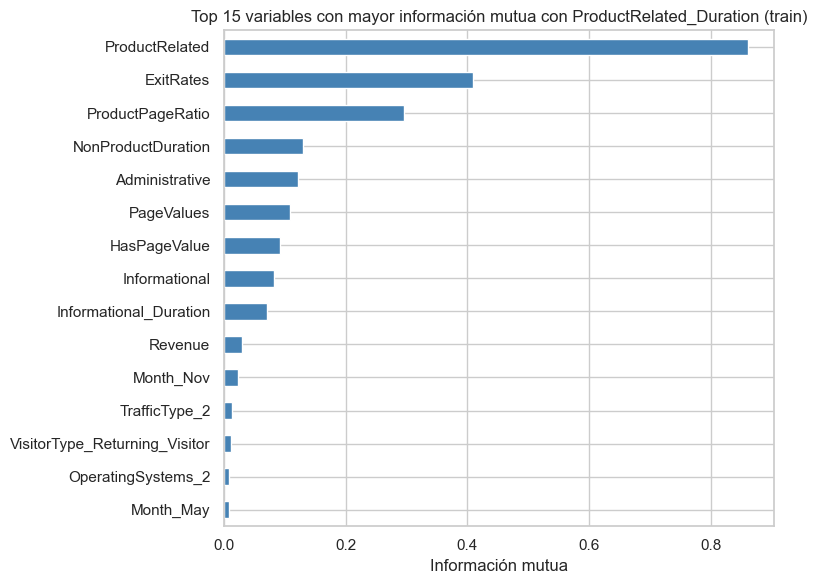

In [48]:
# 2.4 Filtro de información mutua
UMBRAL_MI = 0.001
CARACTERISTICAS = [c for c in conservadas if mi[c] > UMBRAL_MI]
descartadas_mi = [c for c in conservadas if mi[c] <= UMBRAL_MI]

print(f"Descartadas por información mutua <= {UMBRAL_MI} ({len(descartadas_mi)}):")
print(descartadas_mi)
print(f"\nResumen: {X_train.shape[1]} variables iniciales -> {len(CARACTERISTICAS)} seleccionadas")
print(CARACTERISTICAS)

# Gráfica Top 15
plt.figure(figsize=(8, 6))
mi[CARACTERISTICAS].head(15).sort_values().plot(kind="barh", color="steelblue")
plt.title(f"Top 15 variables con mayor información mutua con {TARGET} (train)")
plt.xlabel("Información mutua")
plt.tight_layout()
plt.show()

### 2.5 ¿Sirvió la selección de características?
Se compara el desempeño promedio de la Regresión Lineal en validación cruzada (5 folds dentro de `train`) usando las 72 variables frente a usar únicamente las 38 variables seleccionadas.

In [49]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

pipe_rl = Pipeline([
    ("escalador", StandardScaler()),
    ("modelo", LinearRegression()),
])

metricas_cv = {
    "MAE": "neg_mean_absolute_error",
    "MSE": "neg_mean_squared_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}

res_todas = cross_validate(pipe_rl, X_train, y_train, cv=cv, scoring=metricas_cv)
res_sel = cross_validate(pipe_rl, X_train[CARACTERISTICAS], y_train, cv=cv, scoring=metricas_cv)

comparativa_sel = pd.DataFrame({
    f"Todas ({X_train.shape[1]} vars)": [
        -res_todas["test_MAE"].mean(),
        -res_todas["test_MSE"].mean(),
        -res_todas["test_RMSE"].mean(),
        res_todas["test_R2"].mean(),
    ],
    f"Seleccionadas ({len(CARACTERISTICAS)} vars)": [
        -res_sel["test_MAE"].mean(),
        -res_sel["test_MSE"].mean(),
        -res_sel["test_RMSE"].mean(),
        res_sel["test_R2"].mean(),
    ],
}, index=["MAE", "MSE", "RMSE", "R2"])

display(comparativa_sel)

,Todas (72 vars),Seleccionadas (38 vars)
MAE,500.7426,495.9004
MSE,"926,264.1933","924,315.4833"
RMSE,951.5693,950.4652
R2,0.7529,0.7536


## 3. Entrenamiento y validación cruzada (Regresión Lineal)

**Justificación del flujo de entrenamiento**
- Usar las **38 variables seleccionadas** resulta indispensable: con las 72 variables originales, las categorías *dummy* casi vacías producen colinealidad exacta en ciertos pliegues de validación cruzada y hacen explotar el error; tras filtrar varianza, correlación e información mutua, el modelo alcanza un **$R^2$ promedio de 0.7536** en validación cruzada.
- Se encapsula `StandardScaler()` y `LinearRegression()` dentro de un `Pipeline` para escalar cada pliegue de manera independiente (sin fuga de datos) y permitir comparar directamente la magnitud de los coeficientes estandarizados ($\beta_i$).

In [50]:
X_train_sel = X_train[CARACTERISTICAS]
X_test_sel = X_test[CARACTERISTICAS]

# Resultados detallados por cada fold de validación cruzada
scores_folds = cross_validate(pipe_rl, X_train_sel, y_train, cv=cv, scoring=metricas_cv)

tabla_folds = pd.DataFrame({
    "Fold": [f"Fold {i+1}" for i in range(5)],
    "MAE": -scores_folds["test_MAE"],
    "MSE": -scores_folds["test_MSE"],
    "RMSE": -scores_folds["test_RMSE"],
    "R2": scores_folds["test_R2"],
}).set_index("Fold")

tabla_folds.loc["Promedio CV"] = tabla_folds.mean()
tabla_folds.loc["Desv. Estándar CV"] = tabla_folds.iloc[:5].std()
display(tabla_folds)

# Entrenamiento definitivo sobre todo el conjunto train seleccionado
modelo_rl = pipe_rl.fit(X_train_sel, y_train)

,MAE,MSE,RMSE,R2
Fold,,,,
Fold 1,486.2738,"1,507,856.3977","1,227.9480",0.6698
Fold 2,497.2476,"749,437.5721",865.7006,0.7907
Fold 3,507.4831,"791,375.7508",889.5930,0.7207
Fold 4,483.3740,"674,025.1444",820.9903,0.8066
Fold 5,505.1237,"898,882.5513",948.0942,0.7800
Promedio CV,495.9004,"924,315.4833",950.4652,0.7536
Desv. Estándar CV,10.8469,"336,179.7670",161.7533,0.0570


## 4. Evaluación en `test`

Se evalúa el modelo entrenado una sola vez sobre el conjunto de prueba (`test`, 2,441 sesiones) utilizando las cuatro métricas solicitadas:
- **MAE (Error Absoluto Medio):** error promedio directo en segundos.
- **MSE (Error Cuadrático Medio):** promedio de los errores al cuadrado (en segundos$^2$).
- **RMSE (Raíz del Error Cuadrático Medio):** desviación estándar de los residuos en segundos; penaliza fuertemente errores grandes.
- **$R^2$ (Coeficiente de determinación):** proporción de la varianza de `ProductRelated_Duration` explicada por el modelo.

In [51]:
def evaluar_regresion(modelo, X, y):
    pred = modelo.predict(X)
    return {
        "MAE": mean_absolute_error(y, pred),
        "MSE": mean_squared_error(y, pred),
        "RMSE": root_mean_squared_error(y, pred),
        "R2": r2_score(y, pred),
    }

resultados_test = pd.DataFrame({
    "Línea base (media)": evaluar_regresion(base, X_test, y_test),
    "Regresión Lineal": evaluar_regresion(modelo_rl, X_test_sel, y_test),
}).T

display(resultados_test)

,MAE,MSE,RMSE,R2
Línea base (media),"1,125.2141","3,580,458.0113","1,892.2098",-0.0000
Regresión Lineal,490.6208,"737,787.5125",858.9456,0.7939


## 5. Interpretación del modelo

Se examinan:
1. **Los coeficientes estandarizados ($\beta_i$):** identifican qué características aumentan o reducen el tiempo estimado en páginas de productos.
2. **Gráfica de Valores Reales vs. Predichos y Residuos ($y - \hat{y}$):** permiten evaluar visualmente el ajuste del hiperplano lineal y detectar sesiones atípicas.

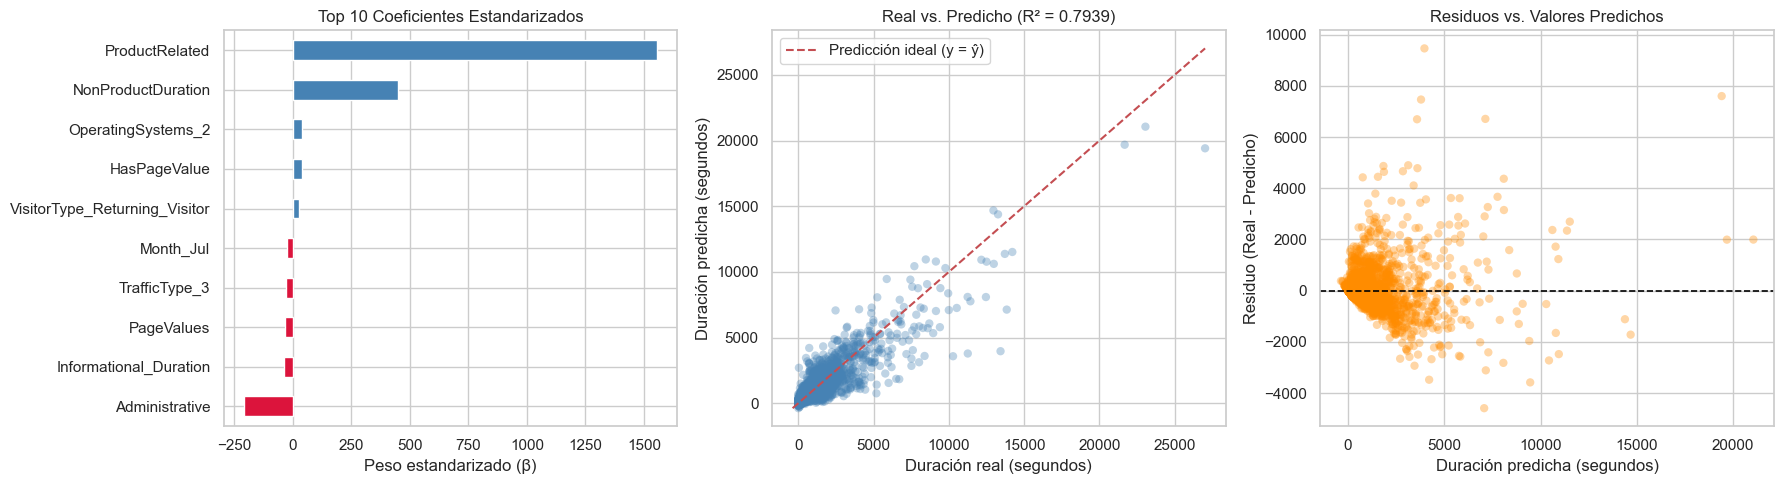

In [52]:
y_pred_test = modelo_rl.predict(X_test_sel)
residuos = y_test - y_pred_test

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Top 10 coeficientes estandarizados más influyentes
coefs = pd.Series(
    modelo_rl.named_steps["modelo"].coef_,
    index=CARACTERISTICAS
)
top_coefs = coefs.reindex(coefs.abs().sort_values(ascending=False).head(10).index).sort_values()
colores = ["crimson" if x < 0 else "steelblue" for x in top_coefs]
top_coefs.plot(kind="barh", ax=axes[0], color=colores)
axes[0].set_title("Top 10 Coeficientes Estandarizados")
axes[0].set_xlabel("Peso estandarizado (β)")

# 2. Valores Reales vs. Valores Predichos
axes[1].scatter(y_test, y_pred_test, alpha=0.35, color="steelblue", edgecolors="none")
lims = [min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())]
axes[1].plot(lims, lims, "r--", lw=1.5, label="Predicción ideal (y = ŷ)")
axes[1].set_title(f"Real vs. Predicho (R² = {r2_score(y_test, y_pred_test):.4f})")
axes[1].set_xlabel("Duración real (segundos)")
axes[1].set_ylabel("Duración predicha (segundos)")
axes[1].legend()

# 3. Gráfico de Residuos vs. Predichos
axes[2].scatter(y_pred_test, residuos, alpha=0.35, color="darkorange", edgecolors="none")
axes[2].axhline(0, color="black", linestyle="--", lw=1.2)
axes[2].set_title("Residuos vs. Valores Predichos")
axes[2].set_xlabel("Duración predicha (segundos)")
axes[2].set_ylabel("Residuo (Real - Predicho)")

plt.tight_layout()
plt.show()

## 6. Conclusiones

- **Desempeño del modelo:** La Regresión Lineal mejoró sustancialmente respecto a la línea base (`DummyRegressor`), logrando en el conjunto `test` un **MAE de 490.62 s**, un **MSE de 737,787.51 s$^2$**, un **RMSE de 858.95 s** (una reducción del 54.6 % frente al RMSE base de 1,892.21 s) y un **$R^2$ de 0.7939** (explicando el **79.39 %** de la varianza de `ProductRelated_Duration`).
- **Variables determinantes:** `ProductRelated` (número de páginas de producto visitadas) es por amplio margen el predictor positivo más fuerte ($\beta = +1,554.52$), seguido de `NonProductDuration` ($\beta = +450.80$), mientras que `Administrative` presenta un efecto neto negativo al controlar por el volumen de páginas ($\beta = -207.07$).
- **Importancia del preprocesamiento:** Excluir `TotalDuration` y `AvgTimePerPage` evitó una fuga de datos trivial, mientras que el filtrado de varianza y multicolinealidad resultó crítico para estabilizar los coeficientes de las variables categóricas codificadas.
- **Limitaciones:** La diferencia entre el MAE (490.62 s) y el RMSE (858.95 s) refleja la presencia de sesiones atípicas extremadamente largas; asimismo, en sesiones con 0 páginas de producto visitadas, el ajuste lineal puede arrojar predicciones ligeramente negativas.